# Laboratorio 7 – Modelación y Simulación (Grupo 11)
Híbrido SD + DES para Aula Abierta (usuarios activos con System Dynamics, clúster de servidores con eventos discretos).
Parámetros del grupo: g = 11 → q = 0.20 + 0.05·((g−1) mod 4) = 0.30 y D = 3 + ((g−1) mod 4) = 5 días.

Este bloque contiene el modelo; los experimentos de cada Task están en las celdas siguientes.

In [1]:
import heapq, math
import numpy as np
from math import factorial
from scipy import stats
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# --- Parámetros fijos del enunciado ---
p, M, U0 = 0.002, 20_000, 100             # Bass: innovación (p), mercado (M), usuarios iniciales
d0, kW, kR, Wok = 0.003, 1.0, 0.5, 0.75   # abandono base, sensibilidad a W y a r, latencia aceptable (s)
a, mu, K = 0.0005, 2.0, 60                # solicitudes/s por usuario, tasa por servidor (1/0.5 s), capacidad M/M/c/K
theta, c0 = 0.7, 4                        # umbral de autoescalado y servidores iniciales
T_WIN, WARM = 720.0, 120.0                # ventana de hora pico y calentamiento (s)
g = 11                                    # grupo
q = 0.20 + 0.05 * ((g - 1) % 4)           # imitación (boca a boca) = 0.30
D = 3 + ((g - 1) % 4)                     # retraso de entrega de servidores (días) = 5

## Teoría de colas M/M/c (sesión de colas)

In [2]:
def erlang_c(c, A):
    """Probabilidad de esperar C(c, A) de Erlang. Válida para A < c (ρ = A/c < 1)."""
    top = A**c / factorial(c) * c / (c - A)
    return top / (sum(A**k / factorial(k) for k in range(c)) + top)

def mmc_theory(lam, c, mu=mu):
    """Métricas teóricas de M/M/c: W = C/(cμ−λ) + 1/μ, Wq = C/(cμ−λ), ρ = λ/(cμ), L = λW, Lq = λWq."""
    A = lam / mu
    C = erlang_c(c, A)
    Wq = C / (c * mu - lam)
    W = Wq + 1 / mu
    return dict(C=C, Wq=Wq, W=W, rho=lam / (c * mu), L=lam * W, Lq=lam * Wq, busy=lam / mu)

def mmck_blocking(lam, c, Kcap, mu=mu):
    """Probabilidad de bloqueo exacta de M/M/c/K (ecuaciones de balance de nacimiento y muerte): P_K."""
    pn = [1.0]
    for n in range(1, Kcap + 1):
        pn.append(pn[-1] * lam / (mu * min(n, c)))
    return pn[-1] / sum(pn)

def mmck_theory(lam, c, Kcap, mu=mu):
    """M/M/c/K exacta (balance de nacimiento y muerte): bloqueo P_K y latencia de las aceptadas W = L/(λ(1−P_K))."""
    pn = [1.0]
    for n in range(1, Kcap + 1):
        pn.append(pn[-1] * lam / (mu * min(n, c)))
    tot = sum(pn); pn = [x / tot for x in pn]
    L = sum(n * x for n, x in enumerate(pn))
    return dict(PK=pn[-1], W=L / (lam * (1 - pn[-1])), L=L)

## Capa DES: cola M/M/c/K simulada por eventos discretos
Las llegadas son Poisson (tiempos entre llegadas exponenciales de tasa λ = a·U) y el servicio es exponencial de media 1/μ.
Disciplina FIFO con c servidores idénticos: cada solicitud aceptada empieza en max(llegada, primer servidor libre).
Una solicitud que llega con K solicitudes en el sistema es rechazada.

In [3]:
def des_window(lam, c, Kcap=K, T=T_WIN, rng=None):
    """Simula una ventana de T segundos con el sistema inicialmente vacío.
    Devuelve, por solicitud: llegada, aceptada (bool), inicio de servicio y salida (la salida puede ser > T: se deja
    drenar el sistema sin nuevas llegadas para no truncar los tiempos en el sistema)."""
    rng = rng or np.random.default_rng()
    if lam <= 0:
        return dict(arr=np.empty(0), acc=np.empty(0, bool), start=np.empty(0), dep=np.empty(0), c=c, T=T)
    n0 = int(lam * T + 6 * math.sqrt(lam * T) + 20)
    arr = np.cumsum(rng.exponential(1 / lam, n0))             # proceso de Poisson: suma de exponenciales
    while arr[-1] < T:
        arr = np.concatenate([arr, arr[-1] + np.cumsum(rng.exponential(1 / lam, n0))])
    arr = arr[arr < T]
    n = len(arr)
    S = rng.exponential(1 / mu, n)                            # tiempos de servicio ~ Exp(μ)
    acc = np.zeros(n, bool); start = np.full(n, np.nan); dep = np.full(n, np.nan)
    free = [0.0] * c                                          # instantes en que se libera cada servidor (heap)
    inside = []                                               # salidas pendientes de los que están en el sistema (heap)
    hpop, hpush = heapq.heappop, heapq.heappush
    for i in range(n):
        t = arr[i]
        while inside and inside[0] <= t:                      # los que ya salieron antes de t
            hpop(inside)
        if len(inside) >= Kcap:                               # sistema lleno: rechazo
            continue
        f = hpop(free)
        s = t if f < t else f                                 # FIFO: empieza cuando haya servidor libre
        d = s + S[i]
        hpush(free, d); hpush(inside, d)
        acc[i], start[i], dep[i] = True, s, d
    return dict(arr=arr, acc=acc, start=start, dep=dep, c=c, T=T)

def _overlap(x0, x1, lo, hi):
    """Longitud de [x0, x1] ∩ [lo, hi] (para promedios en el tiempo sobre la parte medida)."""
    return np.clip(np.minimum(x1, hi) - np.maximum(x0, lo), 0, None)

def window_stats(res, warm=WARM):
    """Métricas de la parte medida [warm, T) de una ventana. Cohorte medida = llegadas con t ≥ warm.
    W = tiempo promedio en el sistema de aceptadas; r = fracción rechazada; el resto sirve para verificar contra la teoría."""
    arr, acc, st, dp, c, T = res['arr'], res['acc'], res['start'], res['dep'], res['c'], res['T']
    meas = arr >= warm
    n_meas = int(meas.sum())
    am = meas & acc
    n_acc = int(am.sum())
    span = T - warm
    out = dict(n_gen=n_meas, n_acc=n_acc, n_rej=n_meas - n_acc)
    out['r'] = (n_meas - n_acc) / n_meas if n_meas else 0.0
    out['W'] = float(np.mean(dp[am] - arr[am])) if n_acc else 1 / mu     # sin datos: solo servicio (1/μ)
    out['Wq'] = float(np.mean(st[am] - arr[am])) if n_acc else 0.0
    out['lam_eff'] = n_acc / span                                         # tasa de llegadas aceptadas
    a_ = acc
    out['L'] = float(_overlap(arr[a_], dp[a_], warm, T).sum() / span)     # promedio temporal de # en el sistema
    out['Lq'] = float(_overlap(arr[a_], st[a_], warm, T).sum() / span)    # ... en la cola
    out['busy'] = float(_overlap(st[a_], dp[a_], warm, T).sum() / span)   # ... en servicio (servidores ocupados)
    out['util'] = out['busy'] / c
    # conservación de entidades en toda la ventana [0, T]: llegaron = atendidas + rechazadas + dentro
    completed = int((acc & (dp <= T)).sum())
    inside = int((acc & (dp > T)).sum())
    out['cons'] = dict(arrived=len(arr), completed=completed, rejected=int((~acc).sum()), inside=inside)
    return out

def des_exchange(lam, c, rng):
    """Interfaz SD→DES→SD: recibe λ y c, devuelve (W, r) de la parte medida de una ventana de hora pico."""
    s = window_stats(des_window(lam, c, K, T_WIN, rng))
    return s['W'], s['r']

## Capa SD: usuarios activos
dU/dt = (p + q·U/M)(M − U) − δU,   δ = δ0 + κW·max(0, W − Wok) + κR·r   (modelo de Bass con abandono, semana 3)

In [4]:
def sd_rhs(U, W=0.0, r=0.0, q_=None, kW_=None, kR_=None):
    """Lado derecho del SD. Con kW=kR=0 (cascada) el DES no afecta a los usuarios."""
    q_ = q if q_ is None else q_
    kW_ = kW if kW_ is None else kW_
    kR_ = kR if kR_ is None else kR_
    delta = d0 + kW_ * max(0.0, W - Wok) + kR_ * r
    return (p + q_ * U / M) * (M - U) - delta * U

def rk4_step(f, U, h):
    """Un paso de Runge-Kutta de cuarto orden para dU/dt = f(U) (autónoma en la ventana: W y r constantes)."""
    k1 = f(U)
    k2 = f(U + 0.5 * h * k1)
    k3 = f(U + 0.5 * h * k2)
    k4 = f(U + h * k3)
    return U + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6

def euler_step(f, U, h):
    return U + h * f(U)

def integrate_fixed(f, U_init, t_end, h, step=rk4_step):
    """Integra con paso fijo h hasta t_end (el último paso se acorta si hace falta). Devuelve t, U."""
    ts, Us = [0.0], [U_init]
    t, U = 0.0, U_init
    while t < t_end - 1e-12:
        hh = min(h, t_end - t)
        U = step(f, U, hh); t += hh
        ts.append(t); Us.append(U)
    return np.array(ts), np.array(Us)

# Solución analítica del SD con abandono constante δ0 (Riccati): dU/dt = α + βU − γU², raíces U+ > 0 > U−
def sd_exact(t, U_init=U0, q_=None, delta=d0):
    q_ = q if q_ is None else q_
    al, be, ga = p * M, q_ - p - delta, q_ / M
    sq = math.sqrt(be**2 + 4 * al * ga)
    Up, Um = (be + sq) / (2 * ga), (be - sq) / (2 * ga)
    R0 = (U_init - Up) / (U_init - Um)
    R = R0 * np.exp(-ga * (Up - Um) * np.asarray(t))
    return (Up - Um * R) / (1 - R)

## Híbrido SD + DES con política de autoescalado
* Cada H días el SD entrega λ = a·U y c al DES y recibe (W, r), que mantiene constantes hasta el siguiente intercambio.
* Evento de estado: ρ_pred = a·U/(c·μ) cruza hacia arriba θ sin pedido pendiente → se piden k servidores que llegan D días después.
* Evento de tiempo: llegada de los servidores; si ρ_pred sigue > θ, se pide otro lote de inmediato.
* detect='event': el cruce se localiza dentro del paso por bisección (RK4 con paso parcial).
  detect='naive': el umbral solo se revisa al final de cada Δt (versión ingenua del Task 2.3).

In [5]:
H_STEP = 0.25   # paso de integración RK4 (días): elegido en el Task 2.2

def run_hybrid(rng, T=100.0, H=1.0, h=H_STEP, th=theta, k=2, Dl=None, c_init=c0, q_=None, kW_=None, kR_=None,
               detect='event', dt_naive=1.0):
    q_ = q if q_ is None else q_
    Dl = D if Dl is None else Dl
    eps = 1e-9
    t, U, c = 0.0, float(U0), c_init
    pend = None                                  # instante de llegada del pedido pendiente
    orders, arrivals = [], []                    # (t, c_antes) de pedidos, instantes de llegada
    next_win = 0.0
    Wc, rc = 0.0, 0.0
    wins = []                                    # (t, W, r, λ, c) de cada intercambio
    grid_t, grid_U, grid_c = [], [], []          # estado en múltiplos de h

    def s_of(Uv, cv):                            # función de evento: ρ_pred − θ
        return a * Uv / (cv * mu) - th

    def f_cur(Uv):
        return sd_rhs(Uv, Wc, rc, q_, kW_, kR_)

    s_last = s_of(U, c)                          # solo para la versión ingenua
    while t < T - eps:
        if t >= next_win - eps:                  # --- intercambio SD → DES → SD ---
            Wc, rc = des_exchange(a * U, c, rng)
            wins.append((t, Wc, rc, a * U, c))
            next_win += H
        if abs(t / h - round(t / h)) < eps and (not grid_t or grid_t[-1] < t - eps):
            grid_t.append(t); grid_U.append(U); grid_c.append(c)
        g_next = (math.floor(t / h + eps) + 1) * h
        t_end = min(g_next, next_win, T, pend if pend is not None else 1e18)
        tau = t_end - t
        U_new = rk4_step(f_cur, U, tau)
        fired = False
        if detect == 'event' and pend is None:
            if s_of(U, c) < 0 <= s_of(U_new, c):  # cruce hacia arriba dentro del paso → localizar el instante
                gfun = lambda x: s_of(rk4_step(f_cur, U, x), c)
                tau_star = brentq(gfun, 0.0, tau, xtol=1e-13)
                t_ev = t + tau_star
                U = rk4_step(f_cur, U, tau_star); t = t_ev
                pend = t + Dl; orders.append((t, c)); fired = True
        if fired:
            continue
        t, U = t_end, U_new
        if detect == 'naive' and abs(t / dt_naive - round(t / dt_naive)) < eps:   # revisión solo cada Δt
            s_now = s_of(U, c)
            if pend is None and s_last < 0 <= s_now:
                pend = t + Dl; orders.append((t, c))
            s_last = s_now
        if pend is not None and t >= pend - eps:  # --- evento de tiempo: llegan los servidores ---
            c += k; arrivals.append(t); pend = None
            if a * U / (c * mu) > th:             # sigue sobre θ → pedido inmediato
                pend = t + Dl; orders.append((t, c))
            s_last = s_of(U, c)
    grid_t.append(t); grid_U.append(U); grid_c.append(c)
    wins_a = np.array(wins)
    days_r5 = H * float((wins_a[:, 2] > 0.05).sum())                  # días (de ventana) con rechazo > 5 %
    excess = H * float(np.maximum(0.0, wins_a[:, 1] - Wok).sum())     # ∫ (W − Wok)+ dt: la parte de W que genera abandono
    return dict(days_r5=days_r5, excess=excess, t=np.array(grid_t), U=np.array(grid_U), c=np.array(grid_c), orders=orders, arrivals=arrivals,
                wins=wins_a, Wmax=float(wins_a[:, 1].max()), rmax=float(wins_a[:, 2].max()),
                U_end=U, c_end=c)

def mean_ci(x, conf=0.95):
    """Media e intervalo de confianza t de Student a partir de réplicas independientes."""
    x = np.asarray(x, float)
    m = x.mean()
    if len(x) < 2:
        return m, 0.0
    return m, stats.t.ppf(0.5 + conf / 2, len(x) - 1) * x.std(ddof=1) / math.sqrt(len(x))

In [6]:
import json, os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

In [7]:
os.makedirs('figs', exist_ok=True); os.makedirs('results', exist_ok=True)
RES = {}                       # resultados numéricos que luego se citan en el informe
def save_res(name):
    with open(f'results/{name}.json', 'w') as fh:
        json.dump(RES, fh, indent=1, default=float)

## Task 1.2 – Equilibrio con capacidad fija (c = 4, sin rechazos)
Con r = 0: W(U) = C(4, aU/μ)/(4μ − aU) + 1/μ  (válida para aU < cμ, es decir U < 16 000).
Equilibrio: (p + qU/M)(M − U) = [δ0 + κW·max(0, W(U) − Wok)]·U.

In [8]:
def f_eq(U, c=4):
    """Lado derecho del SD con r = 0 y W = W_mmc(U): adopción neta menos abandono."""
    W = mmc_theory(a * U, c)['W']
    return sd_rhs(U, W, 0.0)

Wok_U = brentq(lambda U: mmc_theory(a * U, 4)['W'] - Wok, 5_000, 15_900)
Ustar = brentq(f_eq, 11_000, 15_900)
th = mmc_theory(a * Ustar, 4)
print(f"U valida para a*U < c*mu -> U < {4 * mu / a:.0f};  W = Wok en U = {Wok_U:.1f}")
print(f"U* = {Ustar:.1f}, rho = {th['rho']:.4f}, W = {th['W']:.4f} s")
print("f(U):", [(u, round(f_eq(u), 1)) for u in (12_000, 13_000)])
print("equilibrio de la cascada (kW=kR=0):", brentq(lambda U: sd_rhs(U, 0, 0, kW_=0, kR_=0), 1_000, M))

U valida para a*U < c*mu -> U < 16000;  W = Wok en U = 11958.9
U* = 12715.5, rho = 0.7947, W = 0.8574 s
f(U): [(12000, 1363.4), (13000, -775.7)]
equilibrio de la cascada (kW=kR=0): 19801.337702870453


## Task 2.1 – Verificación de la capa DES contra la teoría (sin SD)

In [9]:
NREP = 100                                    # réplicas independientes (≥ 30)
rng = np.random.default_rng(2017)

# a) λ = 6, c = 4, K muy grande: M/M/4 estable (ρ = 0.75)
reps = [window_stats(des_window(6.0, 4, 10**6, T_WIN, rng)) for _ in range(NREP)]
th6 = mmc_theory(6.0, 4)
rows = []
for key, name, teo in [('W', 'Latencia W (s)', th6['W']), ('Wq', 'Espera en cola Wq (s)', th6['Wq']),
                       ('util', 'Utilización ρ', th6['rho'])]:
    m, ci = mean_ci([s[key] for s in reps])
    rows.append((name, teo, m, ci, m - ci <= teo <= m + ci))
df21a = pd.DataFrame(rows, columns=['Métrica', 'Teoría', 'Simulación', 'IC95 ±', 'Teoría dentro del IC'])
print(df21a.to_string(index=False))
RES['t21a'] = df21a.values.tolist()

# b) λ = 10, c = 4, K = 60: sobrecarga
rep_b = [window_stats(des_window(10.0, 4, K, T_WIN, rng)) for _ in range(NREP)]
rb, cib = mean_ci([s['r'] for s in rep_b])
approx = 1 - 4 * mu / 10.0
exact_pk = mmck_blocking(10.0, 4, K)
print(f"r simulada = {rb:.5f} ± {cib:.5f};  1 - c*mu/lam = {approx:.5f};  P_K exacta M/M/4/60 = {exact_pk:.7f}")
print("W de aceptadas en sobrecarga:", mean_ci([s['W'] for s in rep_b]))
RES['t21b'] = dict(r=rb, ci=cib, approx=approx, exact=exact_pk)

# c) Ley de Little con las cantidades de la simulación de (a): L = λ_eff·W, Lq = λ_eff·Wq, servidores ocupados = λ_eff/μ
little = []
for key, wkey, name in [('L', 'W', 'L = λ·W'), ('Lq', 'Wq', 'Lq = λ·Wq'), ('busy', None, 'ocupados = λ/μ')]:
    lhs = np.array([s[key] for s in reps])
    rhs = np.array([s['lam_eff'] * (s[wkey] if wkey else 1 / mu) for s in reps])
    err = np.abs(lhs - rhs) / lhs
    little.append((name, lhs.mean(), rhs.mean(), 100 * (abs(lhs.mean() - rhs.mean()) / lhs.mean()), 100 * err.mean()))
df21c = pd.DataFrame(little, columns=['Relación', 'Lado medido (promedio temporal)', 'Lado Little (λ_eff·tiempo)',
                                      'Error relativo de medias (%)', 'Error relativo medio por réplica (%)'])
print(df21c.to_string(index=False))
RES['t21c'] = df21c.values.tolist()
save_res('task2')

              Métrica   Teoría  Simulación   IC95 ±  Teoría dentro del IC
       Latencia W (s) 0.754717    0.751937 0.009519                  True
Espera en cola Wq (s) 0.254717    0.251595 0.008980                  True
        Utilización ρ 0.750000    0.751278 0.003079                  True


r simulada = 0.19977 ± 0.00312;  1 - c*mu/lam = 0.20000;  P_K exacta M/M/4/60 = 0.2000004
W de aceptadas en sobrecarga: (np.float64(7.003043652427891), np.float64(0.028954774868437578))
      Relación  Lado medido (promedio temporal)  Lado Little (λ_eff·tiempo)  Error relativo de medias (%)  Error relativo medio por réplica (%)
       L = λ·W                         4.518626                    4.520243                      0.035800                              0.142346
     Lq = λ·Wq                         1.513515                    1.513843                      0.021670                              0.183347
ocupados = λ/μ                         3.005110                    3.004392                      0.023909                              1.130453


## Task 2.2 – Verificación de la capa SD (abandono constante δ0)

RK4 (h=0.25) vs solve_ivp(1e-10): error max = 2.967e-03 usuarios; solve_ivp vs analitica = 1.826e-06
RK4 vs analitica: 2.966e-03;  U(100): RK4=19801.3377, solve_ivp=19801.3377


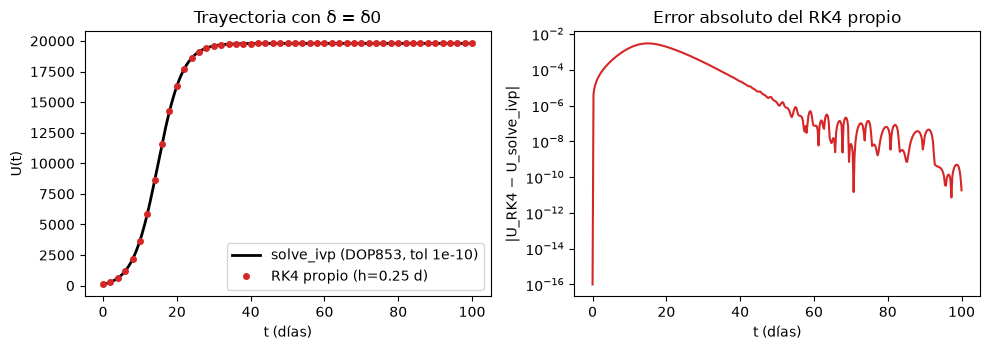

      h       Euler          RK4
4.00000 7204.535210 9.243718e+01
2.00000 4194.631612 8.379756e+00
1.00000 2213.960335 6.516658e-01
0.50000 1126.125512 4.508913e-02
0.25000  567.739989 2.966228e-03
0.12500  284.824670 1.902174e-04
0.06250  142.655957 1.204265e-05
0.03125   71.383700 7.575127e-07
orden Euler = 0.96, orden RK4 = 3.86


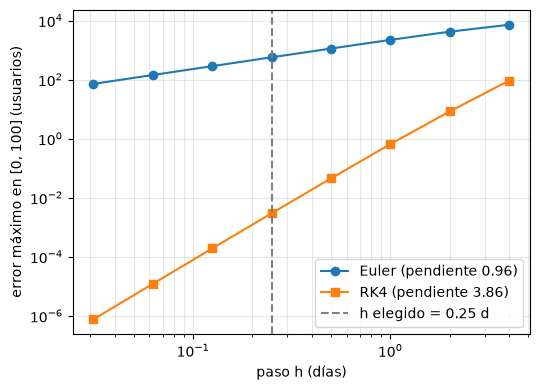

In [10]:
f0 = lambda U: sd_rhs(U, 0.0, 0.0)             # W = r = 0 → δ = δ0
h = H_STEP
t_rk, U_rk = integrate_fixed(f0, U0, 100.0, h, rk4_step)
sol = solve_ivp(lambda t, U: [f0(U[0])], [0, 100], [U0], method='DOP853', rtol=1e-10, atol=1e-10, t_eval=t_rk)
U_ref = sol.y[0]
U_an = sd_exact(t_rk)
e_rk_ivp = np.abs(U_rk - U_ref)
print(f"RK4 (h={h}) vs solve_ivp(1e-10): error max = {e_rk_ivp.max():.3e} usuarios; solve_ivp vs analitica = {np.abs(U_ref - U_an).max():.3e}")
print(f"RK4 vs analitica: {np.abs(U_rk - U_an).max():.3e};  U(100): RK4={U_rk[-1]:.4f}, solve_ivp={U_ref[-1]:.4f}")
RES['t22a'] = dict(h=h, err_rk4_ivp=e_rk_ivp.max(), err_ivp_exact=float(np.abs(U_ref - U_an).max()),
                   U100_rk4=U_rk[-1], U100_ivp=U_ref[-1])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(t_rk, U_ref, 'k-', lw=2, label='solve_ivp (DOP853, tol 1e-10)')
ax[0].plot(t_rk[::8], U_rk[::8], 'o', ms=4, color='tab:red', label=f'RK4 propio (h={h} d)')
ax[0].set_xlabel('t (días)'); ax[0].set_ylabel('U(t)'); ax[0].set_title('Trayectoria con δ = δ0'); ax[0].legend()
ax[1].semilogy(t_rk, np.maximum(e_rk_ivp, 1e-16), color='tab:red')
ax[1].set_xlabel('t (días)'); ax[1].set_ylabel('|U_RK4 − U_solve_ivp|'); ax[1].set_title('Error absoluto del RK4 propio')
plt.tight_layout(); plt.savefig('figs/t22a.png', dpi=150); plt.show()

# b) error máximo contra el paso (referencia: solución analítica)
hs = np.array([4, 2, 1, 0.5, 0.25, 0.125, 0.0625, 0.03125])
err_eu, err_rk = [], []
for hh in hs:
    for step, lst in ((euler_step, err_eu), (rk4_step, err_rk)):
        tt, uu = integrate_fixed(f0, U0, 100.0, hh, step)
        lst.append(np.abs(uu - sd_exact(tt)).max())
err_eu, err_rk = np.array(err_eu), np.array(err_rk)
ok = err_rk > 1e-9                                     # evita el piso de redondeo para estimar el orden de RK4
ord_eu = np.polyfit(np.log(hs), np.log(err_eu), 1)[0]
ord_rk = np.polyfit(np.log(hs[ok]), np.log(err_rk[ok]), 1)[0]
print(pd.DataFrame(dict(h=hs, Euler=err_eu, RK4=err_rk)).to_string(index=False))
print(f"orden Euler = {ord_eu:.2f}, orden RK4 = {ord_rk:.2f}")
RES['t22b'] = dict(h=hs.tolist(), euler=err_eu.tolist(), rk4=err_rk.tolist(), ord_euler=ord_eu, ord_rk4=ord_rk)

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog(hs, err_eu, 'o-', label=f'Euler (pendiente {ord_eu:.2f})')
ax.loglog(hs, err_rk, 's-', label=f'RK4 (pendiente {ord_rk:.2f})')
ax.axvline(H_STEP, color='gray', ls='--', label=f'h elegido = {H_STEP} d')
ax.set_xlabel('paso h (días)'); ax.set_ylabel('error máximo en [0, 100] (usuarios)'); ax.legend(); ax.grid(True, which='both', alpha=.3)
plt.tight_layout(); plt.savefig('figs/t22b.png', dpi=150); plt.show()
save_res('task2')

## Task 2.3 – Autoescalado como evento de estado localizado
Se comparan: evento localizado (bisección dentro del paso) y detección ingenua al final de cada Δt (1 y 0.25 días).
Como el DES solo "ve" c en los instantes de intercambio, se evalúa con H = 1 (base) y con H = 0.25 (ventana fina), y con el
híbrido completo y la cascada (κW = κR = 0), para separar el efecto de la detección del efecto de la retroalimentación.

cruce analitico (SD sin abandono por latencia, W<Wok): t = 15.73771 d


 Modelo    H             Versión  día 1er pedido  día llegada  Wmax (s)      ±     U(100)   ±   rmax      ±  días r>5%      ±  exceso W (s·d)      ±  c final
Híbrido 1.00   Evento localizado         15.7377      20.7377    1.0100 0.0723 19801.3377 0.0 0.0000 0.0000     0.0000 0.0000          0.4633 0.0435      8.0
Híbrido 1.00    Ingenua Δt = 1 d         16.0000      21.0000    1.0100 0.0723 19801.3377 0.0 0.0000 0.0000     0.0000 0.0000          0.4633 0.0435      8.0
Híbrido 1.00 Ingenua Δt = 0.25 d         15.7500      20.7500    1.0100 0.0723 19801.3377 0.0 0.0000 0.0000     0.0000 0.0000          0.4633 0.0435      8.0
Híbrido 0.25   Evento localizado         15.7377      20.7377    1.0877 0.0540 19801.3377 0.0 0.0000 0.0001     0.0000 0.0000          0.4328 0.0136      8.0
Híbrido 0.25    Ingenua Δt = 1 d         16.0000      21.0000    1.0951 0.0532 19801.3377 0.0 0.0000 0.0001     0.0000 0.0000          0.4515 0.0126      8.0
Híbrido 0.25 Ingenua Δt = 0.25 d         15.7500    

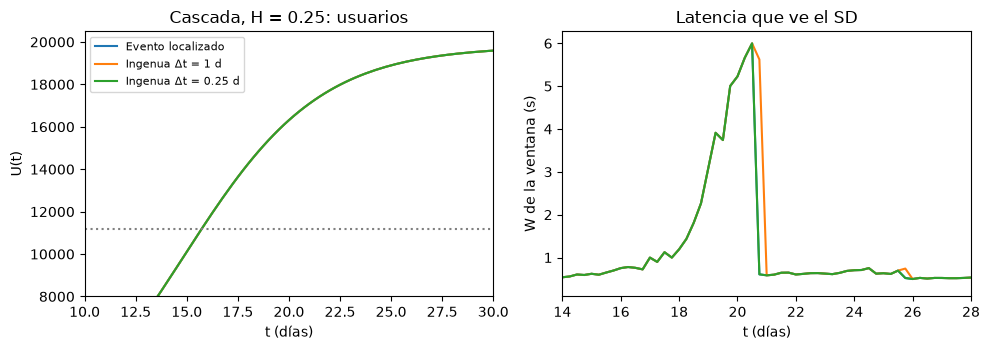

In [11]:
t_cross = brentq(lambda t: sd_exact(t) - theta * 4 * mu / a, 1, 40)   # instante analítico de ρ_pred = θ con c = 4 (sin feedback)
print(f"cruce analitico (SD sin abandono por latencia, W<Wok): t = {t_cross:.5f} d")

versions = [('Evento localizado', dict(detect='event')),
            ('Ingenua Δt = 1 d', dict(detect='naive', dt_naive=1.0)),
            ('Ingenua Δt = 0.25 d', dict(detect='naive', dt_naive=0.25))]
models = [('Híbrido', {}), ('Cascada', dict(kW_=0.0, kR_=0.0))]
NR = 20
cols = ['Modelo', 'H', 'Versión', 'día 1er pedido', 'día llegada', 'Wmax (s)', '±', 'U(100)', '±', 'rmax', '±',
        'días r>5%', '±', 'exceso W (s·d)', '±', 'c final']
rows = []
store = {}
for mname, mkw in models:
    for H_ in (1.0, 0.25):
        for vname, vkw in versions:
            R = [run_hybrid(np.random.default_rng(1000 + i), H=H_, **mkw, **vkw) for i in range(NR)]   # mismas semillas por versión
            store[(mname, H_, vname)] = R
            row = [mname, H_, vname, np.mean([r['orders'][0][0] for r in R]), np.mean([r['arrivals'][0] for r in R])]
            for key in ('Wmax', 'U_end', 'rmax', 'days_r5', 'excess'):
                m, ci = mean_ci([r[key] for r in R]); row += [m, ci]
            row.append(np.mean([r['c_end'] for r in R]))
            rows.append(row)
df23 = pd.DataFrame(rows, columns=cols)
print(df23.round(4).to_string(index=False))
RES['t23'] = dict(t_cross=t_cross, table=df23.values.tolist(), cols=cols)

# trayectoria de una réplica (semilla 1000), cascada con H = 0.25, alrededor del primer pedido
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for (vname, _), col in zip(versions, ['tab:blue', 'tab:orange', 'tab:green']):
    r = store[('Cascada', 0.25, vname)][0]
    ax[0].plot(r['t'], r['U'], color=col, label=vname)
    w = r['wins']
    ax[1].plot(w[:, 0], np.minimum(w[:, 1], 9), color=col, label=vname)
ax[0].axhline(theta * 4 * mu / a, color='gray', ls=':'); ax[0].set_xlim(10, 30); ax[0].set_ylim(8000, 20500)
ax[0].set_xlabel('t (días)'); ax[0].set_ylabel('U(t)'); ax[0].set_title('Cascada, H = 0.25: usuarios'); ax[0].legend(fontsize=8)
ax[1].set_xlim(14, 28); ax[1].set_xlabel('t (días)'); ax[1].set_ylabel('W de la ventana (s)'); ax[1].set_title('Latencia que ve el SD')
plt.tight_layout(); plt.savefig('figs/t23.png', dpi=150); plt.show()

### ¿Cuándo hace más daño la detección tardía? (crecimiento q × retraso D)
Evento localizado vs ingenua Δt = 1 con H = 0.25. T_sat = tiempo libre entre ρ_pred = θ (U = 11 200) y ρ = 1 (U = 16 000) con c = 4:
si D > T_sat, los servidores llegan cuando la cola ya está saturada.

In [12]:
def sat_time(q_):
    f = lambda t, lvl: sd_exact(t, q_=q_) - lvl
    return brentq(lambda t: f(t, 16_000), 1, 80) - brentq(lambda t: f(t, 11_200), 1, 80)

grid = []
NG = 10
for q_ in (0.20, 0.30, 0.50):
    for Dl in (3, 5, 8):
        t_c = brentq(lambda t: sd_exact(t, q_=q_) - 11_200, 1, 80)            # instante del cruce de ρ_pred = θ
        row = dict(q=q_, D=Dl, T_sat=sat_time(q_), t_cruce=t_c, retraso_dt1=math.ceil(t_c) - t_c)   # retraso de la ingenua Δt = 1
        for mname, mkw in models:
            for det, dkw in (('ev', dict(detect='event')), ('nv', dict(detect='naive', dt_naive=1.0))):
                R = [run_hybrid(np.random.default_rng(5000 + i), H=0.25, q_=q_, Dl=Dl, **mkw, **dkw) for i in range(NG)]
                for key in ('Wmax', 'rmax', 'days_r5', 'excess', 'U_end'):
                    row[f'{mname}_{det}_{key}'] = np.mean([r[key] for r in R])
        grid.append(row)
dfg = pd.DataFrame(grid)
for mname in ('Híbrido', 'Cascada'):
    for key in ('Wmax', 'rmax', 'days_r5', 'excess'):
        dfg[f'Δ{key} {mname}'] = dfg[f'{mname}_nv_{key}'] - dfg[f'{mname}_ev_{key}']
print(dfg[['q', 'D', 'T_sat', 'Cascada_ev_days_r5', 'Cascada_nv_days_r5', 'Δdays_r5 Cascada', 'Δexcess Cascada',
           'Δexcess Híbrido', 'Δdays_r5 Híbrido']].round(3).to_string(index=False))
RES['t23grid'] = dfg.round(5).to_dict('records')
save_res('task2')

  q  D  T_sat  Cascada_ev_days_r5  Cascada_nv_days_r5  Δdays_r5 Cascada  Δexcess Cascada  Δexcess Híbrido  Δdays_r5 Híbrido
0.2  3  5.941               0.000               0.000              0.00            0.238            0.026               0.0
0.2  5  5.941               0.000               0.000              0.00            1.121            0.036               0.0
0.2  8  5.941               0.525               0.975              0.45            2.667            0.039               0.0
0.3  3  3.911               0.000               0.000              0.00            0.381            0.024               0.0
0.3  5  3.911               0.200               0.350              0.15            1.251            0.023               0.0
0.3  8  3.911               3.000               3.250              0.25            1.470            0.013               0.0
0.5  3  2.324               0.025               0.025              0.00           -0.000            0.003               0.0
0.5  5  

## Task 2.4 – Verificación de la interfaz SD ↔ DES

30 ventanas: media=2982.3 (esperado 3000), var=3401.9, var/media=1.141, chi2=33.1, p_disp=0.549, p_media(t)=0.107
1000 ventanas: media=3001.43, var=3125.64, var/media=1.041
KS tiempos entre llegadas vs Exp(5): D=0.0023, p=0.833


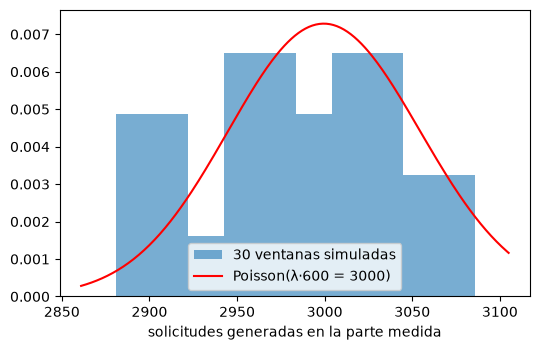

In [13]:
# a) 30 ventanas con λ = 5: número de solicitudes generadas en la parte medida (t ∈ [120, 720) → 600 s)
rng = np.random.default_rng(24)
def counts(n, lam=5.0, c=4):
    out = []
    for _ in range(n):
        res = des_window(lam, c, K, T_WIN, rng)
        out.append(int((res['arr'] >= WARM).sum()))
    return np.array(out)
n30 = counts(30)
mu_hat, var_hat = n30.mean(), n30.var(ddof=1)
exp_n = 5.0 * (T_WIN - WARM)
chi = 29 * var_hat / mu_hat                    # índice de dispersión: (n−1)·s²/x̄ ~ χ²(n−1) si el conteo es Poisson
p_disp = 2 * min(stats.chi2.cdf(chi, 29), stats.chi2.sf(chi, 29))
t_stat, p_mean = stats.ttest_1samp(n30, exp_n)
n1000 = counts(1000)
print(f"30 ventanas: media={mu_hat:.1f} (esperado {exp_n:.0f}), var={var_hat:.1f}, var/media={var_hat / mu_hat:.3f}, "
      f"chi2={chi:.1f}, p_disp={p_disp:.3f}, p_media(t)={p_mean:.3f}")
print(f"1000 ventanas: media={n1000.mean():.2f}, var={n1000.var(ddof=1):.2f}, var/media={n1000.var(ddof=1) / n1000.mean():.3f}")
# tiempos entre llegadas ~ Exp(λ): prueba de Kolmogorov-Smirnov sobre una ventana larga
ia = np.diff(des_window(5.0, 4, K, 20 * T_WIN, rng)['arr'])
ks = stats.kstest(ia, 'expon', args=(0, 1 / 5.0))
print(f"KS tiempos entre llegadas vs Exp(5): D={ks.statistic:.4f}, p={ks.pvalue:.3f}")
RES['t24a'] = dict(n30=n30.tolist(), mean=mu_hat, var=var_hat, expected=exp_n, disp=var_hat / mu_hat, chi2=chi, p_disp=p_disp,
                   p_mean=p_mean, mean1000=n1000.mean(), var1000=n1000.var(ddof=1), ks_D=ks.statistic, ks_p=ks.pvalue)

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.hist(n30, bins=10, density=True, alpha=.6, label='30 ventanas simuladas')
xs = np.arange(n30.min() - 20, n30.max() + 20)
ax.plot(xs, stats.poisson.pmf(xs, exp_n), 'r-', label=f'Poisson(λ·600 = {exp_n:.0f})')
ax.set_xlabel('solicitudes generadas en la parte medida'); ax.legend(); plt.tight_layout(); plt.savefig('figs/t24a.png', dpi=150); plt.show()

In [14]:
# b) conservación de entidades por ventana: llegaron = atendidas + rechazadas + dentro (al cierre de la ventana, t = 720)
cases = [(2, 4), (4, 4), (6, 4), (7, 4), (8, 4), (9, 4), (10, 4), (12, 4), (16, 4), (10, 6), (20, 4), (3, 2)]
rows = []
for lam, c in cases:
    res = des_window(float(lam), c, K, T_WIN, rng)
    cs = window_stats(res)['cons']
    suma = cs['completed'] + cs['rejected'] + cs['inside']
    # comprobación independiente de la cota K: replay de eventos para obtener el máximo de solicitudes en el sistema
    ev = np.concatenate([res['arr'][res['acc']], res['dep'][res['acc']]])
    sg = np.concatenate([np.ones(res['acc'].sum()), -np.ones(res['acc'].sum())])
    o = np.lexsort((sg, ev))
    maxN = int(np.cumsum(sg[o]).max())
    rows.append((lam, c, cs['arrived'], cs['completed'], cs['rejected'], cs['inside'], suma, cs['arrived'] - suma, maxN))
df24b = pd.DataFrame(rows, columns=['λ', 'c', 'Llegaron', 'Atendidas', 'Rechazadas', 'Dentro', 'Suma', 'Diferencia', 'Máx. en sistema'])
print(df24b.to_string(index=False))
bad = 0
for _ in range(500):
    lam = rng.uniform(1, 20); c = int(rng.integers(1, 9))
    cs = window_stats(des_window(lam, c, K, T_WIN, rng))['cons']
    bad += cs['arrived'] != cs['completed'] + cs['rejected'] + cs['inside']
print("ventanas aleatorias con balance roto (de 500):", bad)
RES['t24b'] = dict(table=df24b.values.tolist(), broken_of_500=int(bad))

 λ  c  Llegaron  Atendidas  Rechazadas  Dentro  Suma  Diferencia  Máx. en sistema
 2  4      1479       1476           0       3  1479           0                8
 4  4      2909       2909           0       0  2909           0                9
 6  4      4353       4346           0       7  4353           0               27
 7  4      4999       4993           0       6  4999           0               42
 8  4      5668       5608           3      57  5668           0               60
 9  4      6614       5661         896      57  6614           0               60
10  4      7295       5863        1374      58  7295           0               60
12  4      8343       5770        2516      57  8343           0               60
16  4     11500       5813        5627      60 11500           0               60
10  6      7068       7060           0       8  7068           0               33
20  4     14385       5740        8585      60 14385           0               60
 3  2      2173 

ventanas aleatorias con balance roto (de 500): 0


In [15]:
# c) sesgo de no descartar el calentamiento: sistema vacío al inicio de cada ventana (K = 60, como en el modelo)
NREP2 = 300
rows = []
for lam, c in [(6.0, 4), (7.2, 4), (7.6, 4), (10.0, 4)]:
    th_ = mmck_theory(lam, c, K)
    for warm in (0.0, 120.0, 300.0):
        ss = [window_stats(des_window(lam, c, K, T_WIN, rng), warm=warm) for _ in range(NREP2)]
        mW, cW = mean_ci([s['W'] for s in ss]); mr, cr = mean_ci([s['r'] for s in ss])
        rows.append((lam, c, warm, mW, cW, th_['W'], mr, cr, th_['PK']))
df24c = pd.DataFrame(rows, columns=['λ', 'c', 'calentamiento (s)', 'W sim', '±', 'W teoría M/M/c/K', 'r sim', '± r', 'r teoría'])
print(df24c.round(4).to_string(index=False))
RES['t24c'] = df24c.values.tolist()
save_res('task2')

   λ  c  calentamiento (s)  W sim      ±  W teoría M/M/c/K  r sim    ± r  r teoría
 6.0  4                0.0 0.7506 0.0057            0.7547 0.0000 0.0000    0.0000
 6.0  4              120.0 0.7571 0.0066            0.7547 0.0000 0.0000    0.0000
 6.0  4              300.0 0.7488 0.0076            0.7547 0.0000 0.0000    0.0000
 7.2  4                0.0 1.4662 0.0327            1.4690 0.0003 0.0001    0.0002
 7.2  4              120.0 1.4877 0.0383            1.4690 0.0003 0.0001    0.0002
 7.2  4              300.0 1.4550 0.0426            1.4690 0.0002 0.0001    0.0002
 7.6  4                0.0 2.2803 0.0611            2.3425 0.0024 0.0004    0.0026
 7.6  4              120.0 2.3426 0.0683            2.3425 0.0023 0.0004    0.0026
 7.6  4              300.0 2.3458 0.0766            2.3425 0.0026 0.0005    0.0026
10.0  4                0.0 6.8465 0.0158            7.0000 0.1930 0.0015    0.2000
10.0  4              120.0 7.0043 0.0171            7.0000 0.2003 0.0018    0.2000
10.0

## Task 1.1 – Contraste de las predicciones con los resultados simulados
Las predicciones se escribieron antes de simular y no se modificaron; aquí solo se comparan con los resultados.
(a) híbrido contra cascada (κW = κR = 0); (b) día del primer pedido y servidores en el día 100;
(c) efecto de H = 1 → 7 (comparación preliminar con 20 réplicas; el barrido completo está en el Task 3.1).

In [16]:
NP = 30
hyb = [run_hybrid(np.random.default_rng(2000 + i)) for i in range(NP)]
cas = [run_hybrid(np.random.default_rng(2000 + i), kW_=0.0, kR_=0.0) for i in range(NP)]
rows = []
for name, R in (('Híbrido', hyb), ('Cascada', cas)):
    row = [name]
    for key in ('U_end', 'Wmax', 'rmax'):
        m, ci = mean_ci([r[key] for r in R]); row += [m, ci]
    row += [np.mean([r['orders'][0][0] for r in R]), np.mean([r['c_end'] for r in R]),
            np.mean([r['U'][80] for r in R]),                     # U en el día 20 (justo antes de que lleguen los servidores)
            np.mean([r['U'][:81].max() for r in R])]              # máximo de U hasta el día 20
    rows.append(row)
df11 = pd.DataFrame(rows, columns=['Modelo', 'U(100)', '±', 'Wmax', '±', 'rmax', '±', 'día 1er pedido', 'c(100)',
                                   'U(día 20)', 'máx U hasta día 20'])
print(df11.round(4).to_string(index=False))
print("c(100) en cada réplica (híbrido):", sorted(set(r['c_end'] for r in hyb)), " segundo pedido (día medio):",
      np.mean([r['orders'][1][0] for r in hyb]))
RES['t11ab'] = df11.values.tolist()

 Modelo     U(100)   ±   Wmax      ±   rmax     ±  día 1er pedido  c(100)  U(día 20)  máx U hasta día 20
Híbrido 19801.3377 0.0 1.0684 0.0467 0.0000 0.000         15.7377     8.0 12217.3272          13328.2583
Cascada 19801.3377 0.0 4.8070 0.2651 0.0304 0.006         15.7377     8.0 16312.3848          16312.3848
c(100) en cada réplica (híbrido): [8]  segundo pedido (día medio): 24.80254845546856


In [17]:
# (c) H = 1 vs H = 7, con H = 0.25 como referencia; error relativo cuadrático medio de U(t) por réplica pareada (misma semilla)
NH = 20
runsH = {H_: [run_hybrid(np.random.default_rng(3000 + i), H=H_) for i in range(NH)] for H_ in (0.25, 1.0, 7.0)}
ref = runsH[0.25]
rows = []
for H_ in (1.0, 7.0):
    errs = [np.sqrt(np.mean(((r['U'] - rr['U']) / rr['U'])**2)) for r, rr in zip(runsH[H_], ref)]
    row = [H_]
    for vals in ([r['Wmax'] for r in runsH[H_]], [r['rmax'] for r in runsH[H_]], [r['U_end'] for r in runsH[H_]], errs):
        m, ci = mean_ci(vals); row += [m, ci]
    rows.append(row)
df11c = pd.DataFrame(rows, columns=['H', 'Wmax', '±', 'rmax', '±', 'U(100)', '±', 'ECM relativo de U(t) vs H=0.25', '±'])
print(df11c.round(5).to_string(index=False))
RES['t11c'] = df11c.values.tolist()
save_res('task2')

  H    Wmax       ±  rmax   ±     U(100)   ±  ECM relativo de U(t) vs H=0.25       ±
1.0 1.05018 0.09079   0.0 0.0 19801.3377 0.0                         0.01996 0.00856
7.0 0.60717 0.01531   0.0 0.0 19801.3377 0.0                         0.06234 0.00196
